In [1]:
import sys
import os

sys.path.append("..")

from pytorch_lightning.loggers import CometLogger
from pathlib import Path
from datetime import datetime, timedelta
from lib.wpt_utils import load_wavelets
from training.logging_utils import log_metrics
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytorch_lightning as pl
import json
from scipy.spatial.distance import mahalanobis, cosine
from pydantic import BaseModel

In [2]:
path_train = Path("../data/embeddings/sequence_train")
path_valid = Path("../data/embeddings/sequence_valid")
path_test = Path("../data/embeddings/sequence_test")

In [3]:
def extract_arrays(df: pd.DataFrame) -> tuple[np.ndarray, np.ndarray, list[datetime]]:
    x = []
    t = []
    for cable in [0, 1, 2, 3]:
        df_cable = df.loc[df.cable == cable].copy()
        df_cable.sort_values("sampled_at")
        x.append(np.array(df_cable["values"].to_list()))
        sampled_at = df_cable["sampled_at"].to_list()
        t.append(np.array(df_cable["tension"].to_list()))
    x = np.array(x)
    t = np.array(t)
    return x, t, sampled_at

In [4]:
def load_raw_data(path: Path) -> list[dict]:
    data = []
    for f in os.listdir(path):
        d = json.load(open(path / f))
        for cable in [0, 1, 2, 3]:
            content = d[f"c{cable}"]
            content["sampled_at"] = d["sampled_at"]
            data.append(content)
    return data

In [5]:
train_data = load_raw_data(path_train)
valid_data = load_raw_data(path_valid)
test_data = load_raw_data(path_test)

In [6]:
df_train = pd.DataFrame([o for o in train_data])
df_valid = pd.DataFrame([o for o in valid_data])
df_test = pd.DataFrame([o for o in test_data])

In [7]:
df_train["sampled_at"] = pd.to_datetime(df_train["sampled_at"])
df_valid["sampled_at"] = pd.to_datetime(df_valid["sampled_at"])
df_test["sampled_at"] = pd.to_datetime(df_test["sampled_at"])

In [8]:
df_train = df_train.sort_values("sampled_at")
df_valid = df_valid.sort_values("sampled_at")
df_test = df_test.sort_values("sampled_at")

In [28]:
def resample_df(df: pd.DataFrame, freq: str = "1D") -> pd.DataFrame:

    def func(x):
        if len(x) == 0:
            return None
        x_arr = np.array(x.to_list())
        x_arr_mean = x_arr.mean(axis=0)
        x_arr_p75 = np.quantile(x_arr, 0.75, axis=0)
        x_arr_p25 = np.quantile(x_arr, 0.25, axis=0)
        return np.concatenate([x_arr_mean, x_arr_p75, x_arr_p25])
        #return np.array(x.to_list()).mean(axis=0)

    df_list = []
    for cable in [0, 1, 2, 3]:
        temp = df.loc[df.cable == cable].copy().set_index("sampled_at")
        temp = temp.resample("1D").agg(
            {"tension": "mean", "values": func, "cable": "first"}
        )
        df_list.append(temp)
    return pd.concat(df_list).reset_index()

In [29]:
df_train_rs = resample_df(df_train, freq="1D")
df_valid_rs = resample_df(df_valid, freq="1D")
df_test_rs = resample_df(df_test, freq="1D")

x_train, t_train, s_train = extract_arrays(df_train_rs)
x_valid, t_valid, s_valid = extract_arrays(df_valid_rs)
x_test, t_test, s_test = extract_arrays(df_test_rs)

In [36]:
x_train.shape

(4, 69, 12)

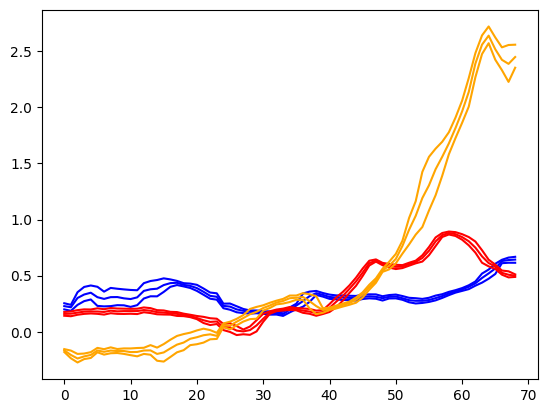

In [43]:
plt.plot(x_train[0,:,0], color='blue')
plt.plot(x_train[0,:,4], color='blue')
plt.plot(x_train[0,:,8], color='blue')

plt.plot(x_train[1,:,0], color='red')
plt.plot(x_train[1,:,4], color='red')
plt.plot(x_train[1,:,8], color='red')

plt.plot(x_train[2,:,0], color='orange')
plt.plot(x_train[2,:,4], color='orange')
plt.plot(x_train[2,:,8], color='orange')

# Other

In [11]:
def get_reference_idx(s: list[datetime], ref_date: datetime) -> int:
    for i, date in enumerate(s):
        if date >= ref_date:
            return i
    return -1

In [12]:
train_idx = get_reference_idx(s_train, s_train[0] + timedelta(weeks=2))
valid_idx = get_reference_idx(s_valid, s_valid[0] + timedelta(weeks=2))
test_idx = get_reference_idx(s_test, s_test[0] + timedelta(weeks=2))

In [13]:
train_ref = x_train[:, :train_idx, :]
valid_ref = x_valid[:, :valid_idx, :]
test_ref = x_test[:, :test_idx, :]

In [14]:
def get_polar(embeddings: np.ndarray, ref_vec: np.ndarray = None):
    """
    Plot embeddings in polar coordinates relative to a reference vector.

    Parameters
    ----------
    embeddings : np.ndarray
        Array of shape (n_samples, 4).
    ref_vec : np.ndarray
        Reference vector of shape (4,).
    """
    # Normalize reference vector
    idx_10 = int(0.1 * embeddings.shape[0])
    if ref_vec is None:
        ref_vec = embeddings[:idx_10].mean(axis=0)

    ref_norm = ref_vec / np.linalg.norm(ref_vec)

    # Euclidean distances (radius)
    radii = np.linalg.norm(embeddings - ref_vec, axis=1)

    # Cosine similarity -> angle
    embeddings_norm = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)
    cos_sims = embeddings_norm @ ref_norm
    angles = np.arccos(np.clip(cos_sims, -1, 1))  # ensure numerical stability

    # Assemble on a single array
    polar_coords = np.column_stack((radii, angles))
    return polar_coords

In [15]:
train_polar = np.stack([get_polar(x_train[i]) for i in range(4)])
valid_polar = np.stack([get_polar(x_valid[i]) for i in range(4)])
test_polar = np.stack([get_polar(x_test[i]) for i in range(4)])

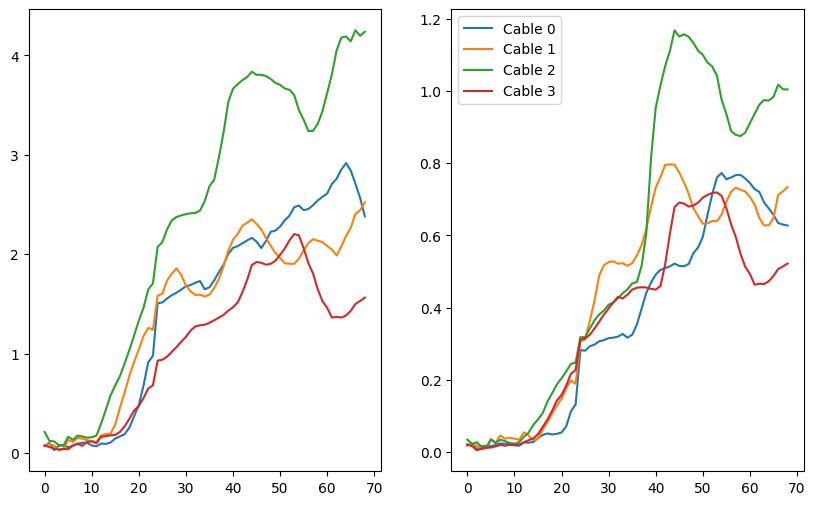

In [16]:
plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
for i in range(4):
    plt.plot(train_polar[i, :, 0])
plt.subplot(1, 2, 2)
for i in range(4):
    plt.plot(train_polar[i, :, 1])
plt.legend(["Cable 0", "Cable 1", "Cable 2", "Cable 3"])

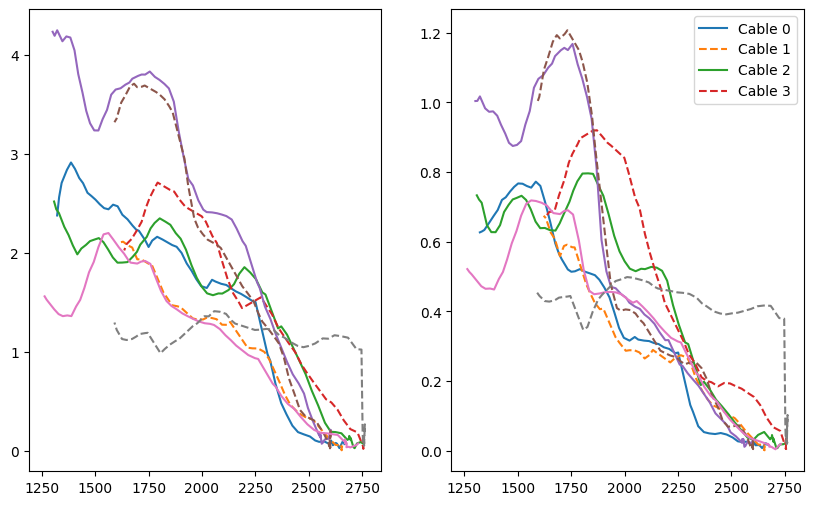

In [17]:
plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
for i in range(4):
    plt.plot(t_train[i], train_polar[i, :, 0])
    plt.plot(t_valid[i], valid_polar[i, :, 0], linestyle="dashed")
plt.subplot(1, 2, 2)
for i in range(4):
    plt.plot(t_train[i], train_polar[i, :, 1])
    plt.plot(t_valid[i], valid_polar[i, :, 1], linestyle="dashed")
plt.legend(["Cable 0", "Cable 1", "Cable 2", "Cable 3"])

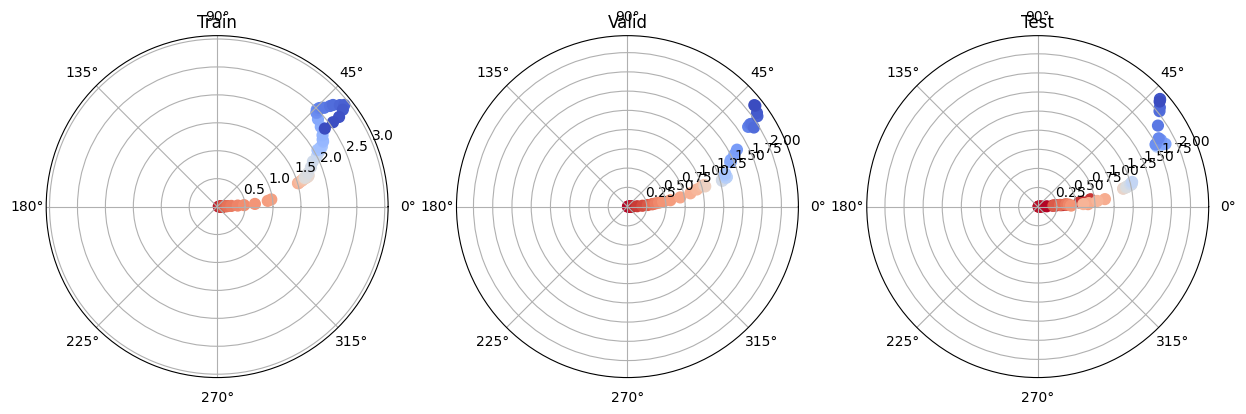

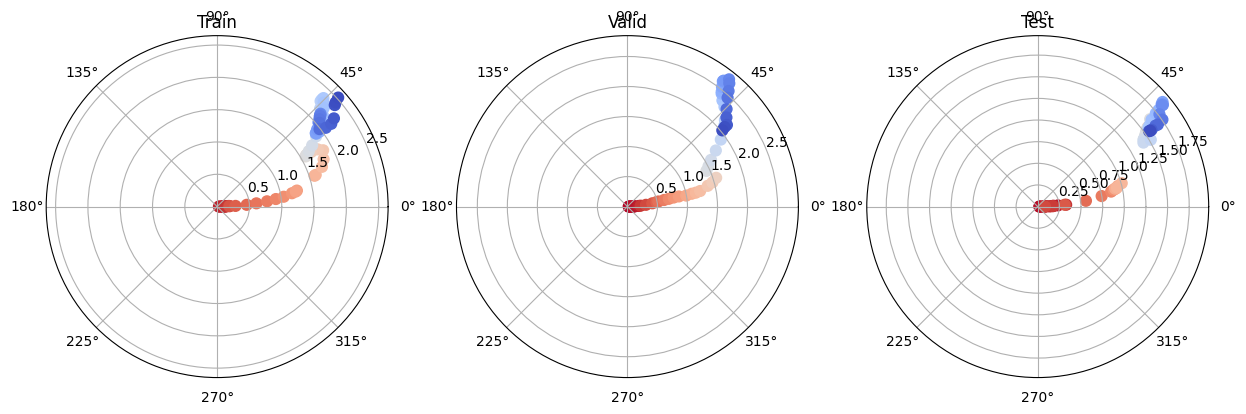

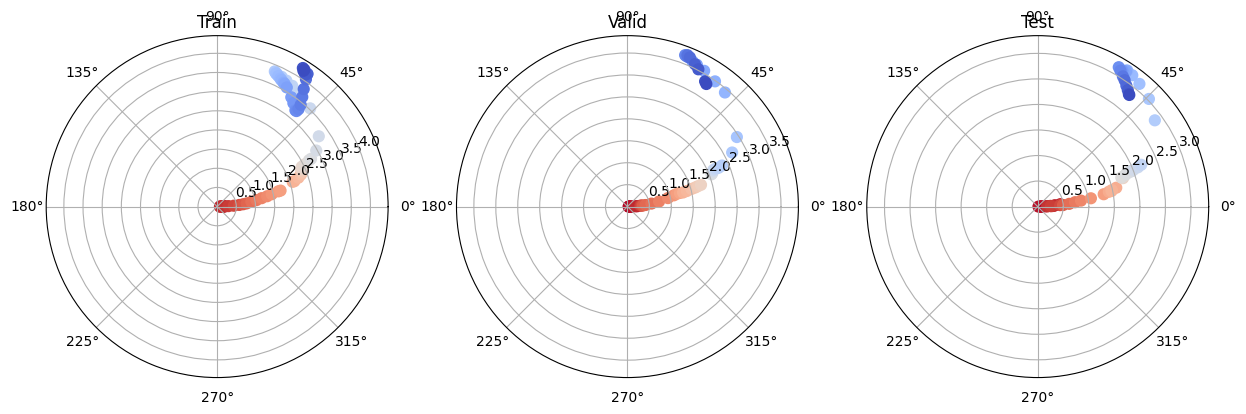

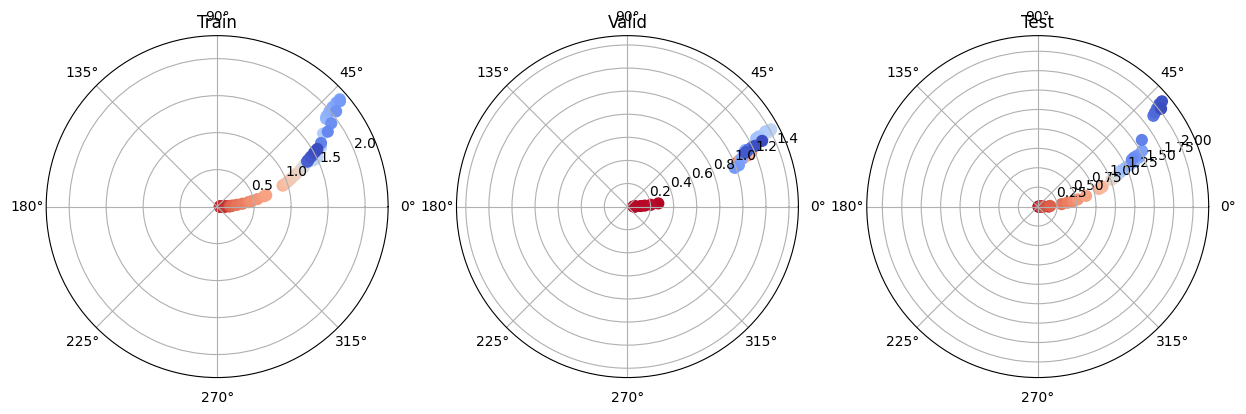

In [18]:
for i in range(4):
    fig = plt.figure(figsize=(15, 8))
    ax = fig.add_subplot(1, 3, 1, polar=True)
    ax.scatter(
        train_polar[i, :, 1],
        train_polar[i, :, 0],
        c=t_train[i],
        s=60,
        label="Train",
        cmap="coolwarm",
    )
    ax.set_title("Train")
    ax = fig.add_subplot(1, 3, 2, polar=True)
    ax.scatter(
        valid_polar[i, :, 1],
        valid_polar[i, :, 0],
        c=t_valid[i],
        s=60,
        label="Valid",
        alpha=1,
        cmap="coolwarm",
    )
    ax.set_title("Valid")
    ax = fig.add_subplot(1, 3, 3, polar=True)
    ax.scatter(
        test_polar[i, :, 1],
        test_polar[i, :, 0],
        c=t_test[i],
        s=60,
        label="Test",
        alpha=1,
        cmap="coolwarm",
    )
    ax.set_title("Test")
    # ax.legend()

In [19]:
from hmmlearn.hmm import GaussianHMM, GMMHMM

In [20]:
def create_lr_transition_matrix(n_states: int) -> np.ndarray:

    # Initialize with zeros
    transmat = np.zeros((n_states, n_states))

    # Set probabilities for self-transition and next-state transition
    for i in range(n_states):
        if i == n_states - 1:
            # Last state only transitions to itself
            transmat[i, i] = 1.0
        else:
            # Other states can transition to self or next state
            transmat[i, i] = 0.5
            transmat[i, i + 1] = 0.5

    return transmat

In [21]:
n_components = 6
model = GaussianHMM(
    n_components=n_components, covariance_type="diag", n_iter=1000, init_params="mc"
)
# model = GMMHMM(n_components=n_components, n_mix=3, covariance_type="diag", n_iter=1000, init_params="mc")
model.transmat_ = create_lr_transition_matrix(n_components)
model.startprob_ = np.array([1.0] + [0.0] * (n_components - 1))

seq_train = [train_polar.shape[1]] * 4  # assuming 4 cables
model.fit(np.log(train_polar.reshape(-1, 2)), lengths=seq_train)

GaussianHMM(init_params='mc', n_components=6, n_iter=1000)

In [22]:
train_s0 = model.predict(np.log(train_polar[0]))
train_s1 = model.predict(np.log(train_polar[1]))
train_s2 = model.predict(np.log(train_polar[2]))
train_s3 = model.predict(np.log(train_polar[3]))

train_s = np.stack([train_s0, train_s1, train_s2, train_s3])

In [23]:
valid_s0 = model.predict(np.log(valid_polar[0]))
valid_s1 = model.predict(np.log(valid_polar[1]))
valid_s2 = model.predict(np.log(valid_polar[2]))
valid_s3 = model.predict(np.log(valid_polar[3]))

valid_s = np.stack([valid_s0, valid_s1, valid_s2, valid_s3])

In [24]:
test_s0 = model.predict(np.log(test_polar[0]))
test_s1 = model.predict(np.log(test_polar[1]))
test_s2 = model.predict(np.log(test_polar[2]))
test_s3 = model.predict(np.log(test_polar[3]))

test_s = np.stack([test_s0, test_s1, test_s2, test_s3])

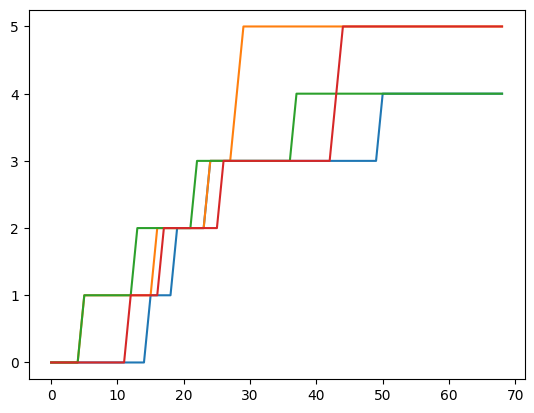

In [25]:
for i in range(4):
    plt.plot(train_s[i])

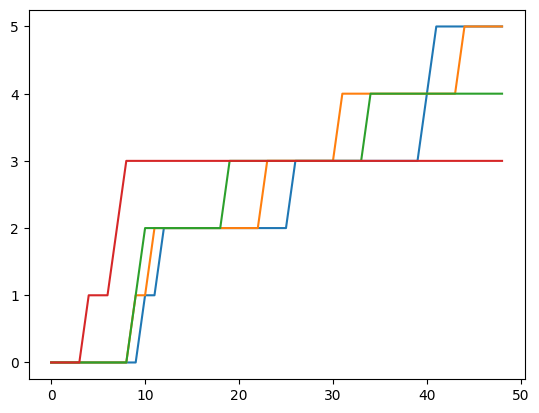

In [26]:
for i in range(4):
    plt.plot(valid_s[i])

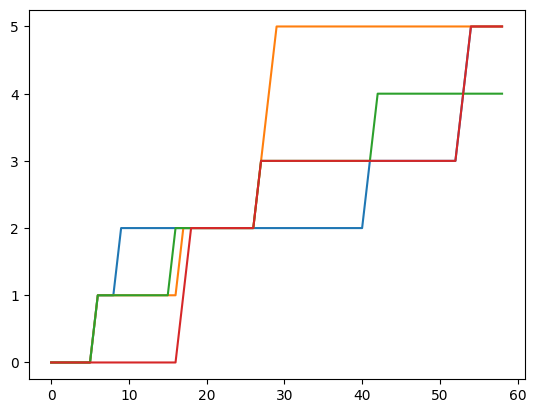

In [27]:
for i in range(4):
    plt.plot(test_s[i])

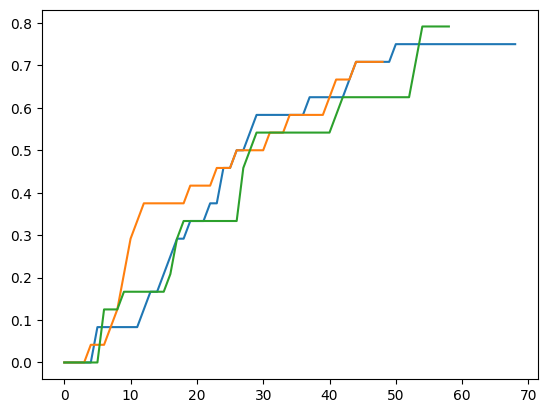

In [28]:
plt.plot(train_s.sum(axis=0) / (n_components * 4))
plt.plot(valid_s.sum(axis=0) / (n_components * 4))
plt.plot(test_s.sum(axis=0) / (n_components * 4))

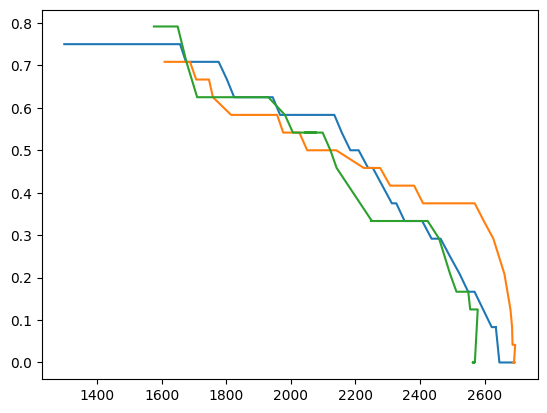

In [29]:
plt.plot(t_train.mean(axis=0), train_s.sum(axis=0) / (n_components * 4))
plt.plot(t_valid.mean(axis=0), valid_s.sum(axis=0) / (n_components * 4))
plt.plot(t_test.mean(axis=0), test_s.sum(axis=0) / (n_components * 4))

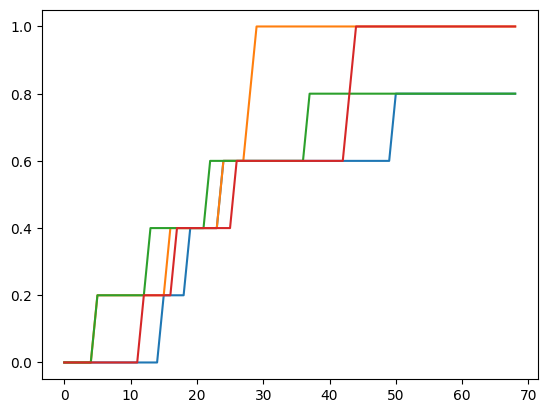

In [30]:
plt.plot(train_s[0] / (n_components - 1))
plt.plot(train_s[1] / (n_components - 1))
plt.plot(train_s[2] / (n_components - 1))
plt.plot(train_s[3] / (n_components - 1))

In [31]:
class HMMState(BaseModel):
    cable: int
    state: int
    norm_state: float
    avg_tension: float
    avg_radius: float
    avg_angle: float


class SampleState(BaseModel):
    sampled_at: str
    num_states: int
    c0: HMMState
    c1: HMMState
    c2: HMMState
    c3: HMMState

In [32]:
def convert_to_obj(
    dates: np.ndarray, s: np.ndarray, t: np.ndarray, polar: np.ndarray, n_components: int
) -> list[SampleState]:
    samples = []
    for n in range(polar.shape[1]):
        sample = SampleState(
            sampled_at=dates[n].isoformat(),
            num_states=n_components,
            c0=HMMState(
                cable=0,
                state=int(s[0, n]),
                norm_state=float(s[0, n] / (n_components - 1)),
                avg_tension=float(t[0, n]),
                avg_radius=float(polar[0, n, 0]),
                avg_angle=float(polar[0, n, 1]),
            ),
            c1=HMMState(
                cable=1,
                state=int(s[1, n]),
                norm_state=float(s[1, n] / (n_components - 1)),
                avg_tension=float(t[1, n]),
                avg_radius=float(polar[1, n, 0]),
                avg_angle=float(polar[1, n, 1]),
            ),
            c2=HMMState(
                cable=2,
                state=int(s[2, n]),
                norm_state=float(s[2, n] / (n_components - 1)),
                avg_tension=float(t[2, n]),
                avg_radius=float(polar[2, n, 0]),
                avg_angle=float(polar[2, n, 1]),
            ),
            c3=HMMState(
                cable=3,
                state=int(s[3, n]),
                norm_state=float(s[3, n] / (n_components - 1)),
                avg_tension=float(t[3, n]),
                avg_radius=float(polar[3, n, 0]),
                avg_angle=float(polar[3, n, 1]),
            ),
        )
        samples.append(sample)
    return samples

In [33]:
train_states = convert_to_obj(s_train, train_s, t_train, train_polar, n_components)
valid_states = convert_to_obj(s_valid, valid_s, t_valid, valid_polar, n_components)
test_states = convert_to_obj(s_test, test_s, t_test, test_polar, n_components)

# Store

In [380]:
import pickle

In [384]:
path_train = Path("../data/states/sequence_train")
path_valid = Path("../data/states/sequence_valid")
path_test = Path("../data/states/sequence_test")

path_model = Path("../data/models/hmm_model.pkl")

In [ ]:
for s in train_states:
    filename = s.sampled_at.replace(":", "-")
    data = s.model_dump()
    with open(path_train / f"{filename}.json", "w") as f:
        json.dump(data, f, indent=4)

for s in valid_states:
    filename = s.sampled_at.replace(":", "-")
    data = s.model_dump()
    with open(path_valid / f"{filename}.json", "w") as f:
        json.dump(data, f, indent=4)

for s in test_states:
    filename = s.sampled_at.replace(":", "-")
    data = s.model_dump()
    with open(path_test / f"{filename}.json", "w") as f:
        json.dump(data, f, indent=4)

In [385]:
with open(path_model, "wb") as f:
    pickle.dump(model, f)